## Simple MultiAI Agent Architecture

In [10]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

In [11]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [12]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [13]:
## Define the state

##MessagesState - MessagesState is a prebuilt state schema in LangGraph that gives your graph a single built-in key, messages, which holds the conversation as a list of message objects (HumanMessage, AIMessage, ToolMessage, etc.).
class AgentState(MessagesState):
    ## important note - message : Annotated[[list], add_messages] ...this is already present in MessageStates

    ## include extra variable next_agent
    next_agent:str #which agent should go next 

In [14]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of findings:\n\n{content[:500]}..."
    return summary

In [15]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(model="openai/gpt-oss-20b", model_provider="groq")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.4', 'langchain': '1.5.2', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002306A25DBD0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002306A25E5D0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [16]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [17]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    writer_llm = llm.bind_tools([write_summary])
    response = writer_llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

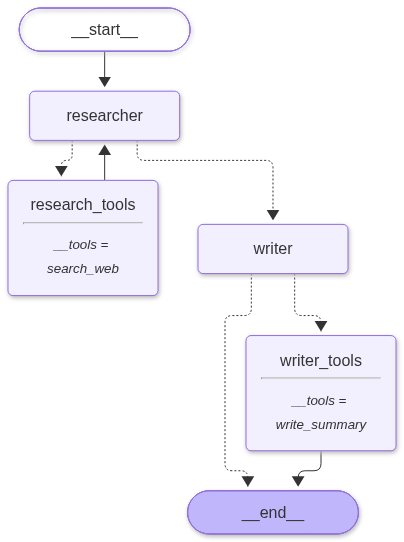

In [18]:
research_tools = ToolNode([search_web])       # researcher's tools only
writer_tools = ToolNode([write_summary])      # writer's tools only

def route_after_researcher(state: AgentState):
    return "research_tools" if state["messages"][-1].tool_calls else "writer"

def route_after_writer(state: AgentState):
    return "writer_tools" if state["messages"][-1].tool_calls else END

workflow = StateGraph(AgentState)

workflow.add_node("researcher", researcher_agent)
workflow.add_node("research_tools", research_tools)
workflow.add_node("writer", writer_agent)
workflow.add_node("writer_tools", writer_tools)

workflow.set_entry_point("researcher")

workflow.add_conditional_edges(
    "researcher", route_after_researcher,
    {"research_tools": "research_tools", "writer": "writer"},
)
workflow.add_edge("research_tools", "researcher")   # search results go back to researcher

workflow.add_conditional_edges(
    "writer", route_after_writer,
    {"writer_tools": "writer_tools", END: END},
)
workflow.add_edge("writer_tools", END)              # tool output is the final answer

final_workflow = workflow.compile()
final_workflow

In [19]:
response=final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in business"})

C:\Users\Admin\AppData\Local\Temp\ipykernel_29352\3356794159.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search = TavilySearchResults(max_results=3)


In [23]:
response

{'messages': [HumanMessage(content='Reasearch about the usecase of agentic ai in business', additional_kwargs={}, response_metadata={}, id='84715df9-9e03-45b1-be74-0faf7516d5d9'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "Reasearch about the usecase of agentic ai in business". They likely want an overview of use cases of agentic AI (i.e., AI systems that can act autonomously, make decisions, etc.) in business. We need to research this. We should use the search_web tool. We\'ll search for "agentic AI use cases in business" or similar. Let\'s do that.', 'tool_calls': [{'id': 'fc_f2cc51a9-250c-405a-993b-8d573c8fb395', 'function': {'arguments': '{"query":"agentic AI use cases in business"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 154, 'total_tokens': 268, 'completion_time': 0.127757613, 'completion_tokens_details': {'reasoning_tokens': 85}, 'prompt_time': 0.007734124,

In [21]:
response["messages"][-1].content

'Summary of findings:\n\n**Agentic AI in Business – Key Findings (2024‑2026)**\n\n1. **What is Agentic AI?**\n   - AI systems that can reason through multi‑step workflows, interact with external APIs or systems, and execute actions autonomously while retaining human oversight.\n\n2. **Primary Business Functions Leveraging Agentic AI**\n   - **Customer Service & Support** – 24/7 chatbots, proactive diagnostics, and automated ticket resolution.  Example: Walmart’s LLM‑powered personal shopping assistant and Klarna’s AI chat han...'